## Using ellc to generate light curves of tidally deformed close-in planets based on the second fluid love number.   

In [1]:
import ellc
import numpy as np
import matplotlib.pylab as plt
import batman
import astropy.constants as c
import astropy.units as u
import Planet_tools as pt
%matplotlib inline

plt.rc('ytick', labelsize=14)
plt.rc('xtick', labelsize=14)

In [2]:
print(ellc.__version__)
print("Installed from https://github.com/tundeakins/ellc")

1.8.6
Installed from https://github.com/tundeakins/ellc


Install using:

```console
git clone https://github.com/tundeakins/ellc.git
cd ellc
python setup.py install
```

This is a modification of the `ellc` transit tool by [Maxted 2016](https://www.aanda.org/articles/aa/full_html/2016/07/aa28579-16/aa28579-16.html) to allow modeling the planet shape, due to tidal deformation, as a function of its Love number $h_f$

### Taking example of WASP_103b

Planet transit parameters are obtained from from [Delrez et al. 2018](https://arxiv.org/pdf/1711.02566.pdf)

In [3]:
P = 0.92554517                                     #days
t0 = 0                                             #mid transit time
aR = 3.010                                         #scaled semimajor axis a/R*
Rv = 0.115                                         # planet radius ratio
inc = 88.8                                         # orbital inclination
b = aR*np.cos(np.deg2rad(inc))
u1, u2 = 0.5343,0.1299
ldc_1 = [u1,u2]                                    #limb darkening parameters 

Mst = 1.21                                         #stellar mass in unit of solar masses
Mp = 1.51* c.M_jup.to( u.Msun).value               #planet mass in unit of solar masses
qmass = Mp/Mst                                     #ratio of planet to stellar mass

phases=np.linspace(-0.1,0.1,300)                   #transit phases to calculate flux


### First compare `batman` light curve to that of `ellc` for a spherical planet

In [4]:
#generate transit light curve using batman

params = batman.TransitParams()
params.t0 = t0                      #time of inferior conjunction
params.per = 1.                     #orbital period
params.rp = Rv                     #planet radius (in units of stellar radii)
params.a = aR                      #semi-major axis (in units of stellar radii)
params.inc = inc                    #orbital inclination (in degrees)
params.ecc = 0                    #eccentricity
params.w = 90.                      #longitude of periastron (in degrees)
params.u = [u1, u2]               #limb darkening coefficients
params.limb_dark = "quadratic"      #limb darkening model


m = batman.TransitModel(params, phases, max_err=0.001)   #initializes model
flux_batman = m.light_curve(params)  #calculates light curve



In [5]:
#for ellc, where both star and planet shapes are set to sphere

r_1 = 1/aR    #radius of star in units of the semimajor axes
r_2 = Rv/aR   #radius of the planet in units of the semimajor axis

ellc_sphere = ellc.lc(phases, t_zero=t0, period=1,
                      radius_1=r_1, radius_2=r_2,
                      incl=inc, sbratio=0,
                      ld_1="quad", ldc_1=ldc_1) 

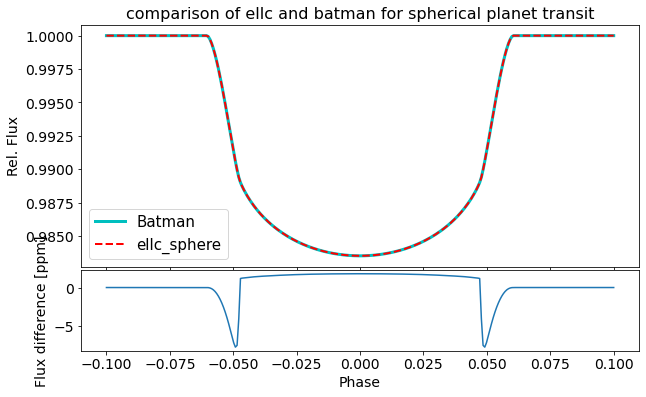

In [6]:
fig, ax = plt.subplots(2,1,figsize=(10,6), gridspec_kw={"height_ratios": (3,1)},sharex=True)

ax[0].plot(phases, flux_batman, "c",lw=3,label="Batman")
ax[0].plot(phases, ellc_sphere, "r--",lw=2,label="ellc_sphere")
ax[0].set_ylabel("Rel. Flux",fontsize=14)
ax[0].set_title("comparison of ellc and batman for spherical planet transit",fontsize=16)
ax[0].legend(fontsize=15)

ax[1].plot(phases, 1e6*(ellc_sphere-flux_batman))

ax[1].set_ylabel("Flux difference [ppm]",fontsize=14);
ax[1].set_xlabel("Phase",fontsize=14);

plt.subplots_adjust(hspace=0.02)


The `batman`  and `ellc` models for a spherical planet agree to <8 ppm as shown also in [Maxted 2016](https://www.aanda.org/articles/aa/full_html/2016/07/aa28579-16/aa28579-16.html)

### Tidally deformed planets

Now to compare deformation using the love number approach following [Correia 2014](https://ui.adsabs.harvard.edu/abs/2014A%26A...570L...5C/abstract) and [Akinsanmi et al 2019](https://www.aanda.org/articles/aa/pdf/2019/01/aa34215-18.pdf)

The second fluid love number is given by $h_f$ and ranges from (0, 2.5) where $h_f=0$ is equivalent to a spherical planet model.

The shape parameter is set as `shape_2` = "love" to model tidal deformation using this approach. The value of $h_f$ is set with `hf_2`. The planet-to-star mass ratio is set with `q`.

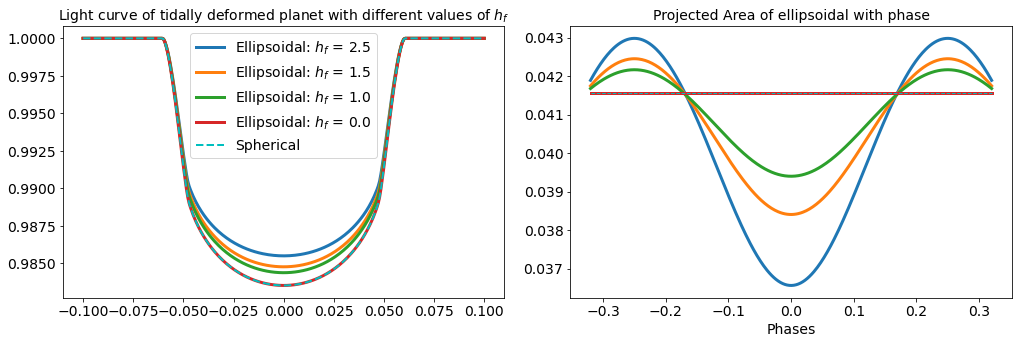

In [7]:
#set shape of the planet shape_2 = "love" and use the following values for hf:
hf_values=[2.5, 1.5, 1, 0]
plot_phases = np.linspace(-0.32,0.32,360)


fig, ax = plt.subplots(1,2,figsize=(17,5))

for h_f in hf_values:
    ellc_flux = ellc.lc(phases,t_zero=t0, 
                        radius_1=r_1,radius_2=r_2,
                        incl=inc,sbratio=0,
                        ld_1="quad",ldc_1=ldc_1,
                        #deformation parameters
                        shape_2='love', q=qmass, hf_2= h_f) 
    
    ax[0].plot(phases, ellc_flux, label = f"Ellipsoidal: $h_f$ = {h_f:.1f}", lw=3)
    
    ellps_area, abc = ellc.projected_ellipse_area(plot_phases, Rv, aR, h_f, qmass, inc)
    ax[1].plot(plot_phases,ellps_area, label = "Ellipsoidal: $h_f$ = {:.1f}".format(h_f), lw=3)




#overplot spherical planet light curve    
ax[0].plot(phases, ellc_sphere, "c--",label="Spherical", lw=2)
ax[1].plot(plot_phases, np.ones_like(plot_phases)*np.pi*Rv**2, "c--",label="Spherical", lw=1)
ax[0].legend(fontsize=14)
ax[0].set_title("Light curve of tidally deformed planet with different values of $h_f$", fontsize=14)
ax[1].set_title("Projected Area of ellipsoidal with phase", fontsize=14)
    
plt.xlabel("Phases", fontsize=14);
plt.subplots_adjust(wspace=0.15)

On the left panel, notice that  the  light-curve  of  the  ellipsoidal model  changes  noticeably  for  different  values  of $h_f$ and  also compared to the spherical case. This is because the ellipsoidal planet projects only a small cross-section of its shape during the transit thereby leading to a lower transit depth when compared to the spherical planet. The plot on the right panel shows how the projected area of the ellipsoid varies (reducing towards mid-transit)

A higher $h_f$ for the same planet causes more deformation, which leads to even smaller projected cross-sectional  area and thus a shallower tansit depth.

The case  where $h_f$ = 0 (although not physical) is used to imply no deformation to the planet so that the ellipsoidal planet model is equivalent to that of a spherical planet (red curve and dashed cyan curve)

### Spherical model fit of simulated transit of deformed WASP-103 (assuming $h_f=1.5$)

In [20]:
from Planet_tools.convert_param import inclination, impact_parameter, convert_LD_coeffs

def model(params,t,pl_shape="sphere",data=None):
    #params[a, rp, b]
    
    r_1 = 1./params[0]                          #Rst/a
    r_2 = params[1]/params[0]                   # Rp/a
    incl = inclination(params[2],params[0])     #inclination 
    #u1_,u2_= params[3],params[4]    
    ldc_1 = [u1,u2]
    ellc_flux = ellc.lc(t, t_zero=t0, radius_1=r_1,radius_2=r_2,
                        incl=incl, sbratio=0,
                        ld_1="quad", ldc_1=ldc_1,
                        shape_2=pl_shape, q=qmass, hf_2=1.5)
    if data is None:
        return ellc_flux
    return np.sum((data - ellc_flux)**2)

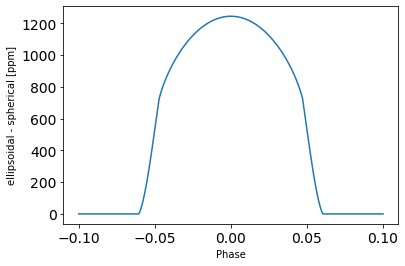

In [22]:
#simulate deformed wasp_103
phase=np.linspace(-0.0863, 0.0863, 230)
params = [aR, Rv, b]

flux_def = model(params, phases, "love")     #simulate deformed
flux_spr = model(params, phases, "sphere")   #use same parameters to simulate spherical

plt.plot(phases,1e6*(flux_def-flux_spr))
plt.ylabel("ellipsoidal - spherical [ppm]")
plt.xlabel("Phase");

As noted previously the ellipsoidal planet has a shallower transit than spherical planet with same parameters. Therefore, if a spherical planet model is used to fit an ellipsoidal planet, the derived spherical radius will need to be smaller than the volumetric radius, $(abc)^{1/3}$, of the ellipsoidal planet in order to match the transit depth.

### Fit deformed planet light curve with spherical model

In [23]:
#fit spherical planet transit to the deformed planet flux(flux_def)
from scipy.optimize import minimize, least_squares, differential_evolution

#result = minimize(model, [aR,Rp,b], args=(phases, "sphere", flux_def), method="trust-constr")
result = differential_evolution( model, args=(phases, "sphere", flux_def), 
                                bounds=((2.5,3.5),(0.08,0.15),(0.,0.5)),
                                popsize=5,polish=True, seed=15)
print(result.x)

[2.98505008 0.11093827 0.14140748]


In [27]:
#transit width of ellipsoidal planet and spherical planet fit
aR_sphr, Rp_sphr, b_sphr= result.x                          #, u1_sphr, u2_sphr 

#calculate transit width
W_ellps14 = pt.calculate_param.transit_duration(P,Rv,aR,b=b)/P


In [28]:
print(f"Spherical planet model gives a planet radius of {Rp_sphr:.4f} that is smaller than the volumetric radius ({Rv:.4f}) used for the simulated ellipsoidal planet")

Spherical planet model gives a planet radius of 0.1109 that is smaller than the volumetric radius (0.1150) used for the simulated ellipsoidal planet


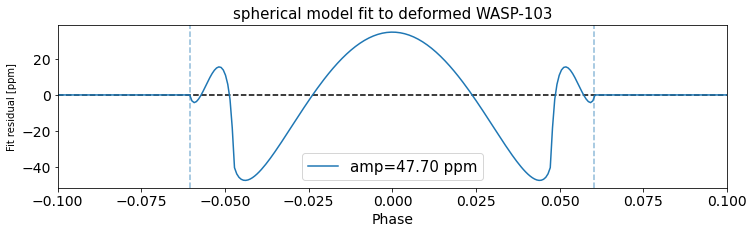

In [29]:
spr_fit = model(result.x,phases,"sphere")
plt.figure(figsize=(12,3))
plt.title("spherical model fit to deformed WASP-103",fontsize=15)
plt.axhline(c="k",ls="dashed")

plt.plot(phases, 1e6*(flux_def-spr_fit), label="amp={:.2f} ppm".format(np.max(np.abs(1e6*(flux_def-spr_fit)))) )
plt.autoscale(enable=True, axis='x', tight=True)
plt.legend(fontsize=15)
plt.xlabel("Phase", fontsize=14)
plt.ylabel("Fit residual [ppm]");
plt.axvline(-W_ellps14/2, ls="dashed", alpha=0.5)
plt.axvline(W_ellps14/2, ls="dashed", alpha=0.5)

### compare the projected area of the ellipsoid to the constant area of the fitted spherical planet area.

In [30]:
area_sphere = np.pi * Rp_sphr**2
plot_phases = np.linspace(-0.5,0.5,10000)
ellps_area, abc = ellc.projected_ellipse_area(plot_phases, Rv, aR, 1.5, qmass, inc)


(-0.5, 0.5)

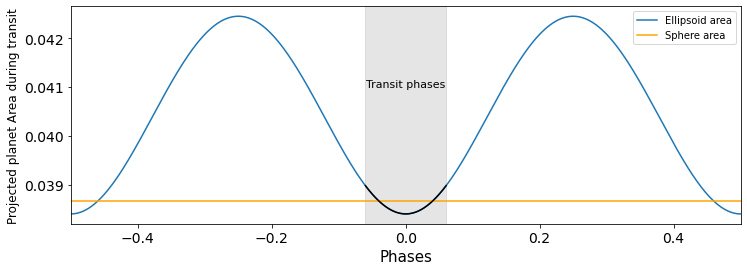

In [31]:

plt.figure(figsize=(12,4))
plt.plot(plot_phases,ellps_area,label="Ellipsoid area")
plt.axhline(area_sphere,label="Sphere area", c="orange")

tran = ellps_area[np.abs(plot_phases)<W_ellps14/2]
plt.plot(plot_phases[np.abs(plot_phases)<W_ellps14/2],tran,"k")


plt.ylabel("Projected planet Area during transit", fontsize=12)
plt.xlabel("Phases", fontsize=15)
plt.legend()
plt.axvspan(-W_ellps14/2, W_ellps14/2, color="gray", alpha=0.2)
plt.text(-0.06,0.041,"Transit phases", fontsize=11)


plt.xlim([min(plot_phases),max(plot_phases)])

#find the two intersection phases  of ellipsoidal area and spherical area curves
# intersect_pts = np.argwhere(np.isclose(ellps_area,area_sphere,atol=1e-7)).reshape(-1)
# plt.plot(plot_phases[intersect_pts], ellps_area[intersect_pts],"o")

As the ellpsoid turns, its projected shape varies leading to variations in the ellipse it projects. Whereas the best fit spherical planet projects a constant circular area irrespective of phase.

The phases during transit are shaded in gray. The ellipsoid projects its minimum area at mid transit when the radial deformation is pointing directly at the star and not observable.

#### Normalize by the spherical planet area

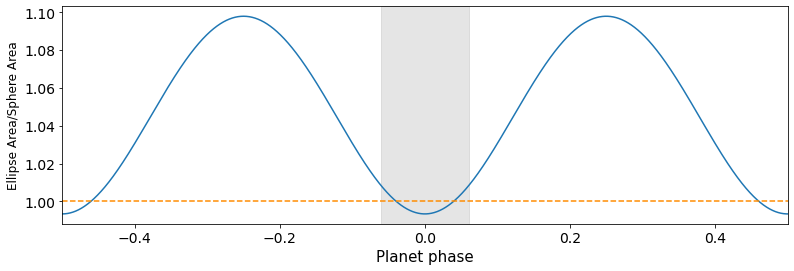

In [32]:
plt.figure(figsize=(13,4))

plt.plot(plot_phases,(ellps_area/area_sphere),label="Ellipse area")
plt.ylabel("Ellipse Area/Sphere Area", fontsize=12)

plt.axhline(1, c = "darkorange", ls="dashed")
plt.axvspan(-W_ellps14/2, W_ellps14/2, color="gray", alpha=0.2)

plt.xlim([-0.5,0.5])
#plt.ylim([0.99,1.02])
plt.xlabel("Planet phase", fontsize=15);


## Estimating $h_f$ for JWST observation

In [191]:
from Planet_tools.convert_param import inclination, impact_parameter, convert_LD_coeffs
from uncertainties.umath import sqrt, sin, cos, asin,log, exp,log10
from Planet_tools.utils import dynesty_results, MaxLL_result_CI
import numpy as np
from uncertainties import ufloat
import astropy.constants as c
import astropy.units as u
import ellc
import matplotlib.pyplot as plt
%matplotlib inline


In [154]:
P = 0.92554517                                     #days
t0 = 0                                             #mid transit time
aR = 3.010                                         #scaled semimajor axis a/R*
Rv = 0.13                                         # planet radius ratio
# inc = 88.8                                         # orbital inclination
b = 0.043#aR*np.cos(np.deg2rad(inc))                                   #limb darkening parameters 

Mst=ufloat(1.21, 0.11)                                        #stellar mass in unit of solar masses
Mp = ufloat(1.51,0.11)*  c.M_jup.to( u.Msun).value               #planet mass in unit of solar masses
qmass = Mp/Mst                                     #ratio of planet to stellar mass

lnqmass = log(qmass)
lnqmass

-6.732734902450944+/-0.11649569777488841

In [155]:
#ellc model for deformed (ellipsoidal) planet
def model(params,t, pl_shape="love"):
    #params[aR,rp,b,hf,q1,q2,t0,log_qmass]
    
    r_1 = 1./params[0]                                   #Rst/a
    r_2 = params[1]/params[0]                            # Rp/a
    incl = np.rad2deg(np.arccos(params[2]/params[0]))    #inclination
    ld_1 = 'power-2'
    c,a= convert_LD_coeffs(params[3],params[4],"q2ca",False)        #convert kippinglD to quadratic
    ldc_1 = [c, a]
    hf = params[5]  if pl_shape=='love' else 0                                      #love number

    qmass = np.exp(lnqmass.n) #np.exp(params[6]) if pl_shape == 'love' else  1                            # Mp/Mst
    #print(qmass)
    
    elps_pl=ellc.lc(t, t_zero=0, radius_1=r_1, radius_2=r_2, incl=incl, sbratio=0, ld_1=ld_1, ldc_1=ldc_1,
                    shape_1='sphere', shape_2=pl_shape, grid_1='default', grid_2='default',
                    q=qmass,hf_2=hf)
    return elps_pl

In [156]:
phase=np.linspace(-0.0863, 0.0863, 230)  #1min cadence

In [221]:
c, a =   ufloat(0.2280,0.0067/2),  ufloat(0.4832,0.0210/2)     #quad ld for jwst from exoctk
q1, q2 = convert_LD_coeffs(c,a, "ca2q")
b = impact_parameter(inc, aR)
q1,q2, b

(0.7003870311996659+/-0.004476454637880503,
 0.9224615063721083+/-0.0018882073901712274,
 0.06303668384890472)

In [222]:
initial = [3.010, 0.115, b, q1.n, q2.n, 1.5, lnqmass.n]

y = model(initial, phase,"love")

rn = np.random.randint(0,1313123)
print(f"rn is {rn}")
np.random.seed(1208620)#
nl = 62e-6
yerr = np.random.normal(0,nl,len(phase))
y += yerr


rn is 65293


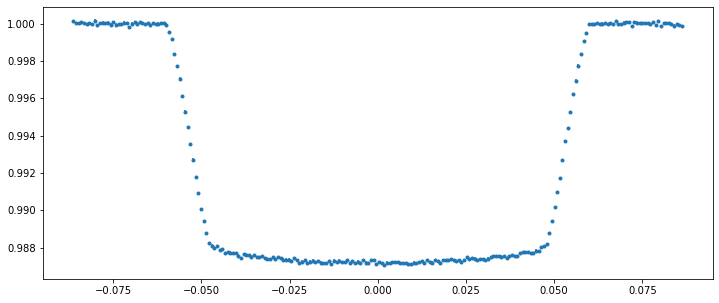

In [223]:
plt.figure(figsize=(12,5))
plt.errorbar(phase, y, yerr=np.ones_like(y)*nl, fmt="." );

In [224]:
from scipy.stats import norm, uniform,loguniform, truncnorm
from better_uniform import buniform as buni

from multiprocessing import Pool
labels=["$a/R_{\\ast}$", "$R_{p}$", "$b$", "$q_{1}$", "$q_{2}$", "$h_{f}$", "lnQ"]#, "ln_$\sigma$"]

a_  = buni(2.8, 3.2)
rp_ = buni(0.08, 0.15) #norm(rp_sphr.n, 10*rp_sphr.s) #
b_  = buni(0.,1)
q1_ = truncnorm((0-q1.n)/q1.s,(1-q1.n)/q1.s, q1.n, q1.s)
q2_ = truncnorm((0-q2.n)/q2.s,(1-q2.n)/q2.s,q2.n, q2.s)
hf_ = buni(0,2.5)
lnq_ = norm(lnqmass.n, lnqmass.s/2)

#ln_sig_ = uniform(-20, 19)

priors = [a_,rp_,b_,q1_,q2_, hf_,lnq_]
ndim= len(priors)
ndim_sp = ndim-2

In [225]:
def prior_transform(u, dim):
    x = np.array(u)    
    for i, pr in enumerate(priors[:dim]):
        x[i] = pr.ppf(u[i])
    return x
 

def lnlike(params, t, y, yerr, pl_shape):
    return -0.5 * np.sum(((y - model(params, t, pl_shape))/yerr) ** 2)

In [226]:
lnlike(initial, phase, y, np.ones_like(y)*62e-6,'love' ), \
lnlike(initial, phase, y, np.ones_like(y)*62e-6,'sphere' )

(-122.76435434492342, -16674.28403707565)

In [227]:
import dynesty
import dynesty.plotting as dyplot

sampler = dynesty.NestedSampler(lnlike,prior_transform, ndim, nlive=200,
                                logl_args= (phase, y, np.ones_like(y)*62e-6, 'love'),
                                ptform_args = (ndim,),
                                pool=Pool(4), queue_size=3)
sampler.run_nested(dlogz=0.01)
res_ellps = sampler.results

4178it [03:20, 20.84it/s, +200 | bound: 59 | nc: 1 | ncall: 25504 | eff(%): 17.166 | loglstar:   -inf < -119.003 <    inf | logz: -135.232 +/-  0.379 | dlogz:  0.000 >  0.010] 


In [228]:
res_ellps.summary()

Summary
nlive: 200
niter: 4178
ncall: 25504
eff(%): 17.166
logz: -135.232 +/-  0.379


In [229]:
sampler2 = dynesty.NestedSampler(lnlike,prior_transform, ndim_sp, nlive=200,
                                logl_args= (phase, y, np.ones_like(y)*62e-6, 'sphere'),
                                ptform_args = (ndim_sp,),
                                pool=Pool(4), queue_size=3)
sampler2.run_nested(dlogz=0.01)
res_sph = sampler2.results

5587it [03:01, 30.84it/s, +200 | bound: 60 | nc: 1 | ncall: 25379 | eff(%): 22.802 | loglstar:   -inf < -119.730 <    inf | logz: -142.987 +/-  0.432 | dlogz:  0.000 >  0.010] 


In [230]:
# results = [res_ellps, res_sph]
# np.save('jwst_model_comparison.npy',results)
# res= np.load("jwst_model_comparison.npy", allow_pickle=True)
# res_ellps, res_sph = res[0], res[1]

In [231]:
res_sph.summary()

Summary
nlive: 200
niter: 5587
ncall: 25379
eff(%): 22.802
logz: -142.987 +/-  0.432


In [234]:
np.exp(res_ellps.logz[-1]- res_sph.logz[-1])

2332.930941505442

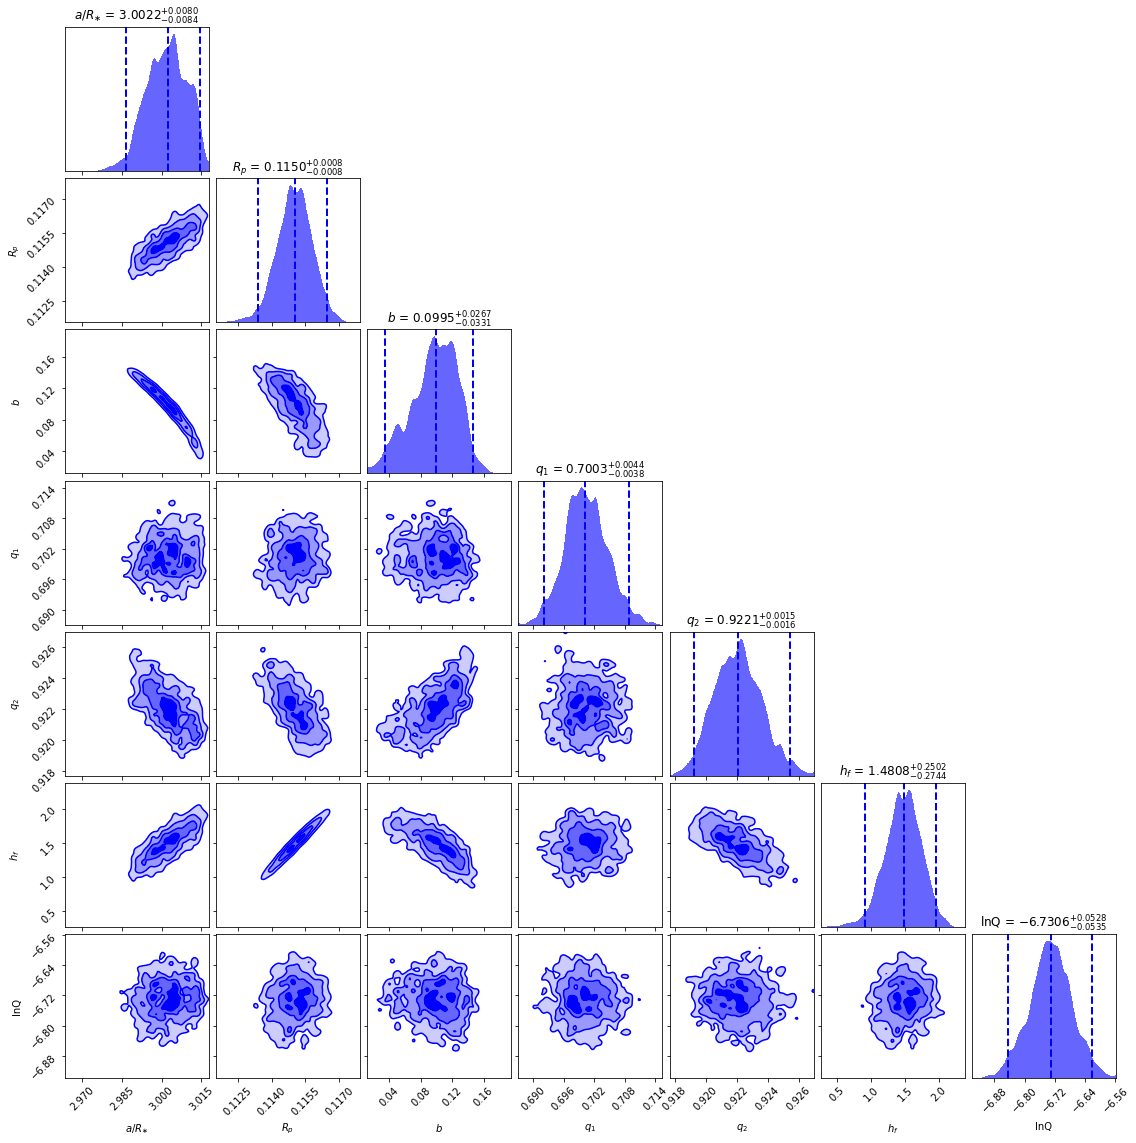

In [233]:
dyplot.cornerplot(res_ellps, labels=labels,show_titles=True,title_fmt=".4f" ,color="b");

In [252]:
1.4808/0.2744

5.396501457725948

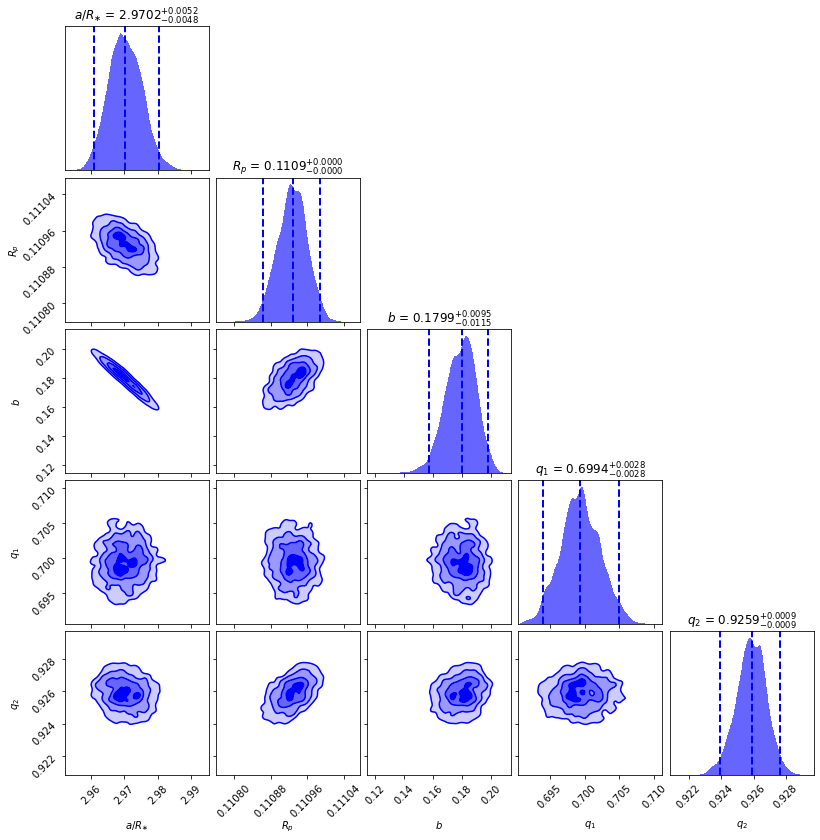

In [215]:
dyplot.cornerplot(res_sph, labels=labels[:ndim_sp],show_titles=True,title_fmt=".4f" ,color="b");

In [235]:
ellps_pars = dynesty_results(res_ellps)
sphr_pars = dynesty_results(res_sph)




ellps_fit = model(ellps_pars, phase,"love")
sphr_fit = model(sphr_pars, phase,"sphere")

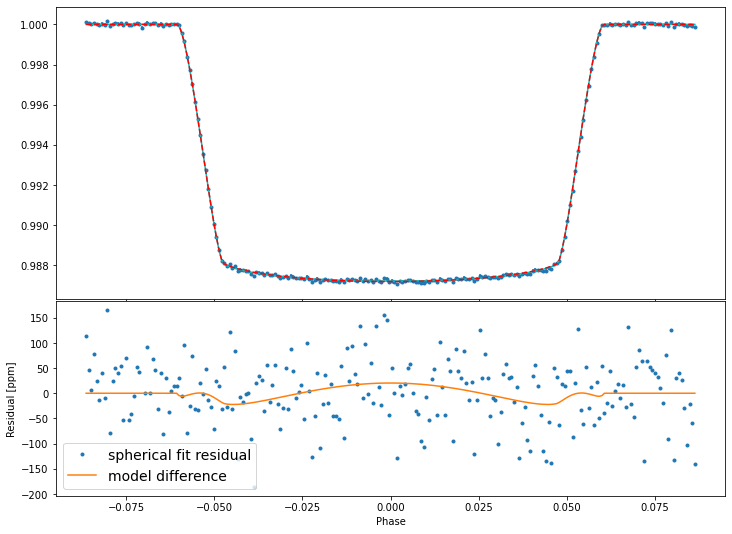

In [250]:
fig, ax = plt.subplots(2,1, figsize=(12,9), gridspec_kw={"height_ratios":(3,2)}, sharex=True)

ax[0].errorbar(phase, y, yerr=np.ones_like(y)*62e-6, fmt=".",zorder=0 );
ax[0].plot(phase, ellps_fit,"c")
ax[0].plot(phase, sphr_fit,"r--")


ax[1].plot(phase, (y-sphr_fit)*1e6,".", label="spherical fit residual")
ax[1].plot(phase, (ellps_fit-sphr_fit)*1e6, label="model difference")
ax[1].set_xlabel("Phase")
ax[1].set_ylabel("Residual [ppm]")
ax[1].legend(fontsize=14)
plt.subplots_adjust(hspace=0.01
                   )

In [251]:
fig.savefig("residual_fit.jpg", dpi=150, bbox_inches="tight")

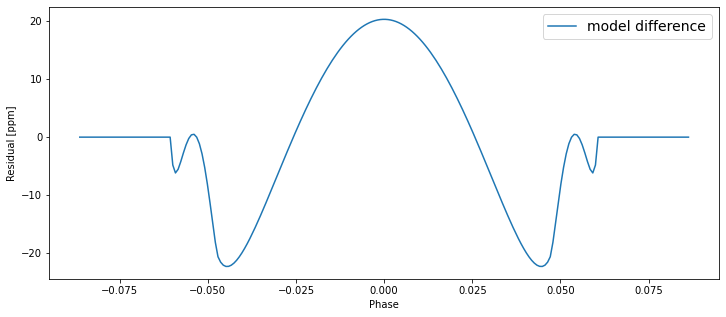

In [253]:
fig = plt.figure(figsize=(12,5))

# plt.plot(phase, (y-sphr_fit)*1e6,".", label="spherical fit residual")
plt.plot(phase, (ellps_fit-sphr_fit)*1e6, label="model difference")
plt.xlabel("Phase")
plt.ylabel("Residual [ppm]")
plt.legend(fontsize=14)

In [134]:
from chainconsumer import ChainConsumer


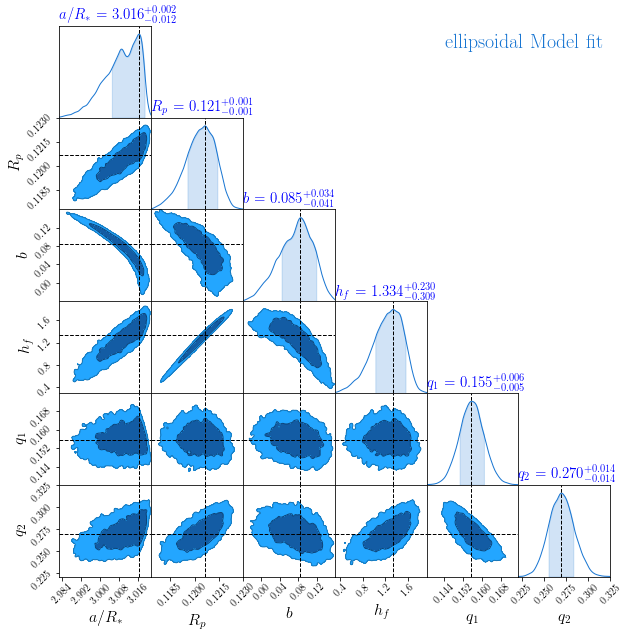

In [138]:
c=ChainConsumer()

c.add_chain(res.samples, labels, "ellipsoidal Model fit", np.exp(res.logwt - res.logz[-1]),color="blue")
c.configure(summary_area=0.68, legend_kwargs={"fontsize":20}, label_font_size=16, smooth=4, statistics="max")

summary = c.analysis.get_summary(squeeze=True)
errs = summary.copy()
for key in summary.keys():
        errs[key] = np.diff(summary[key])
        summary[key] = summary[key][1]

fig = c.plotter.plot( legend=True, truth=summary)

for i in range(len(labels)):
    fig.axes[(len(labels)+1)*i].set_title(
                f" {labels[i]} = {summary[labels[i]]:.3f}$_{{-{errs[labels[i]][0]:.3f}}}^{{+{errs[labels[i]][1]:.3f}}}$",
                                    fontsize=15, color="blue", loc="left")
    

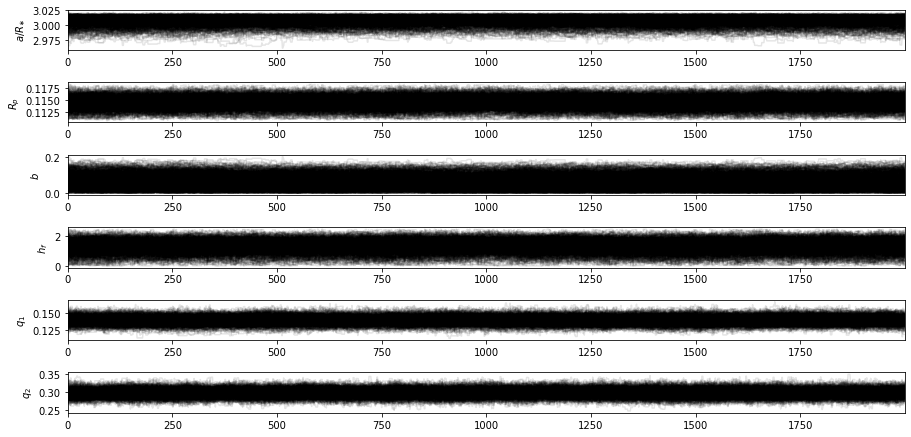

In [242]:
plt.figure(figsize=(15,7))
for j in range(ndim):
    plt.subplot(ndim,1,j+1)
    plt.ylabel(labels[j])
    plt.autoscale(enable=True, axis='x', tight=True)
    for i in range(0,nwalkers-1): plt.plot(sampler.chain[i,3000:, j],"k",alpha=0.1)
    plt.subplots_adjust(hspace=0.8,bottom=0.1, top=0.9)

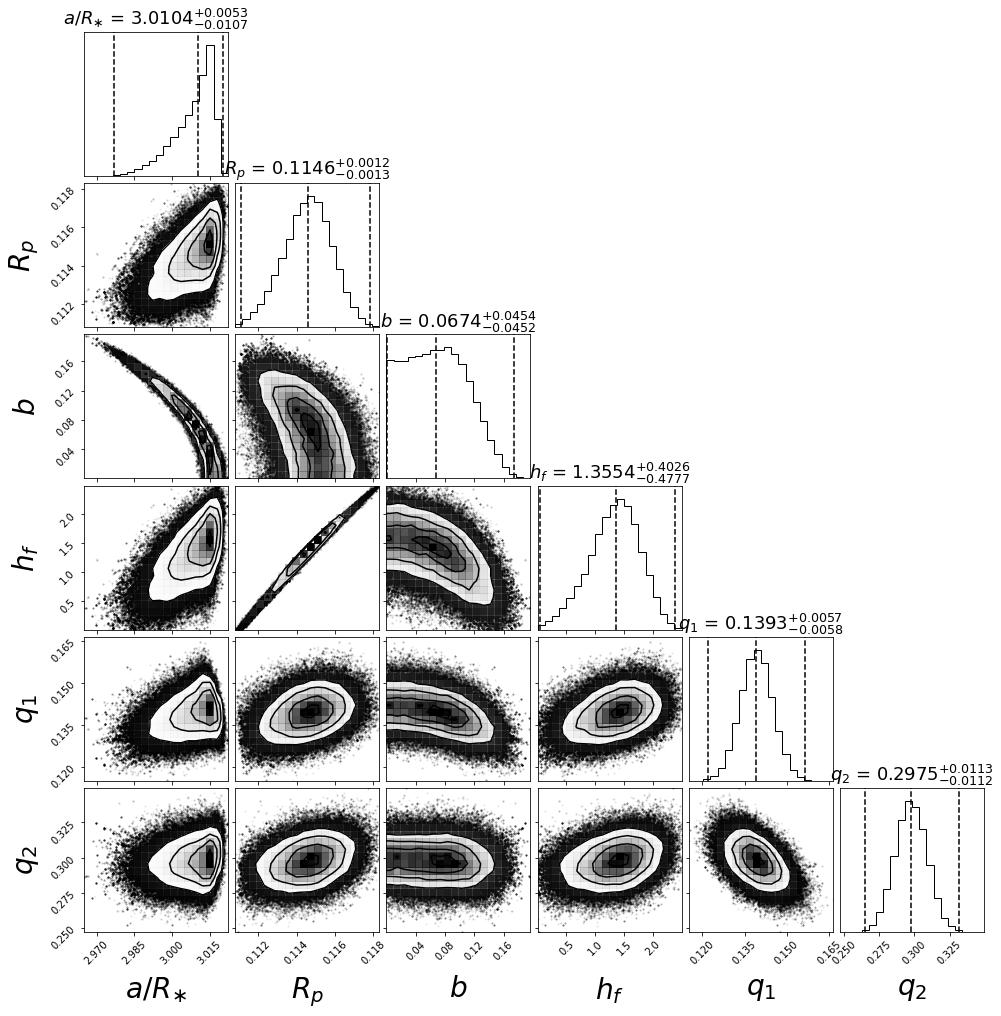

In [240]:
import corner
samples = sampler.chain[:, 4000:, :].reshape((-1, ndim))
fig = corner.corner(samples, labels=labels,show_titles=True,
                    title_fmt=".4f",quantiles=[0.0015,0.5,0.9985],title_kwargs={"fontsize": 18},
                    label_kwargs={"fontsize":28})


In [ ]:
def get_ellipsoidal_Rv(aR,Rspr,b, Mp_Ms,hf=1.5):
    
    def _ellps_model(params,t,pl_shape="sphere", data=None,Mp_Ms=1):
    #params[a,rp,b,t0,q1,q2]
    #     if pl_shape == "sphere": Mp_Ms=1
        r_1 = 1./params[0]                          #Rst/a
        r_2 = params[1]/params[0]                   # Rp/a
        incl = inclination(params[2],params[0])     #inclination 
        #u1_,u2_= params[3],params[4]    
        ldc_1 = [0,0]
        ellc_flux = ellc.lc(t, t_zero=t0, radius_1=r_1,radius_2=r_2,incl=incl,sbratio=0,ld_1="quad",
                        ldc_1=ldc_1,shape_1='sphere',shape_2=pl_shape, grid_1='fine',
                            grid_2='fine',q=Mp_Ms,hf_2=hf)
        if data is None:
            return ellc_flux
        return np.sum((data - ellc_flux)**2) 

    
    phase = np.linspace(-0.1,0.1,300)
    flux_sphr = _ellps_model([aR,Rspr,b], phase)*np.random.normal(1,23*1e-6)
    
    ellps_result = differential_evolution( ellps_model, args=(phase, "love", flux_sphr, Mp_Ms), 
                                bounds=((0.8*aR,1.2*aR),(0.8*Rspr,1.2*Rspr),(max(0.,b-0.1),min(b+0.05,1))),
                                maxiter=500,popsize=15,polish=True)
#     ellps_result = minimize(_ellps_model, np.array([aR,Rspr,b,])*1.001, args=(phase, "love", flux_sphr, Mp_Ms))
    
    plt.plot(phase,flux_sphr,".")
    plt.plot(phase, _ellps_model(ellps_result.x, phase,"love",Mp_Ms=Mp_Ms))
    plt.show()
                                   
    return ellps_result.x

In [ ]:
get_ellipsoidal_Rv( aR_sphr, Rp_sphr, b_sphr, qmass)

In [ ]:
# import corner
# # samples = sampler.chain[:, 2000:, :].reshape((-1, ndim))
# res = sampler.results
# weights = np.exp(res.logwt - res.logz[-1])
# res.samples[:,2] = np.array([inclination(res.samples[i,2],res.samples[i,0]) for i in np.arange(len(res.samples))])
# res.samples[:,3] = res.samples[:,3]/1.319 + 0.5917
# res.samples[:,2] = res.samples[:,2]/87.551*88.2844
# res.samples[:,0] = res.samples[:,0]/3.0018*3.0117
# res.samples[:,1] = res.samples[:,1]/0.1156*0.1165


# truths = params ; truths[2] =88.2
# labels[2] = "$i_p$"
# ranges=[0.9999 for _ in labels]


# fig = corner.corner(res.samples[13000:,:], weights=weights[13000:], labels=labels,show_titles=True,
#                     title_fmt=".3f",quantiles=[0.0015,0.5,0.9985],title_kwargs={"fontsize": 18}, labelpad=0.15,
#                      truths=params, range=ranges, label_kwargs={"fontsize":28},plot_contours=True, smooth=0.4,
#                    max_n_ticks=4, smooth1d=0.2)

# values = [3.0117,0.1165,88.284,1.592,0.5345,0.1304]
# [fig.axes[i*7].axvline(values[i], c="r", lw=2) for i in range(6)];
# fig.set_size_inches(15,10)